<a href="https://colab.research.google.com/github/Gimadikaram/A03-on-CNNs/blob/main/Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


 ## EN3160 – Image Processing and Machine Vision
 ### Assignment 03: Neural Networks
 | Field | Details |
| :--- | :--- |
| **Name** | D.M.G.H. Adikaram |
| **Index Number** | `230018T` |
| **GitHub Repository** | https://github.com/Gimadikaram/A03-on-CNNs |

#### Question 1: Building a Multilayer Perceptron (MLP) with Manual Backpropagation and Cross-Entropy Loss

Using: cuda


100%|██████████| 170M/170M [55:00<00:00, 51.7kB/s]


Epoch  1/10 | Training Loss: 1.8136
Epoch  2/10 | Training Loss: 1.6237
Epoch  3/10 | Training Loss: 1.5274
Epoch  4/10 | Training Loss: 1.4545
Epoch  5/10 | Training Loss: 1.3930
Epoch  6/10 | Training Loss: 1.3391
Epoch  7/10 | Training Loss: 1.2940
Epoch  8/10 | Training Loss: 1.2504
Epoch  9/10 | Training Loss: 1.2113
Epoch 10/10 | Training Loss: 1.1772

Training accuracy after 10 epochs: 60.74%
Test accuracy after 10 epochs: 48.68%


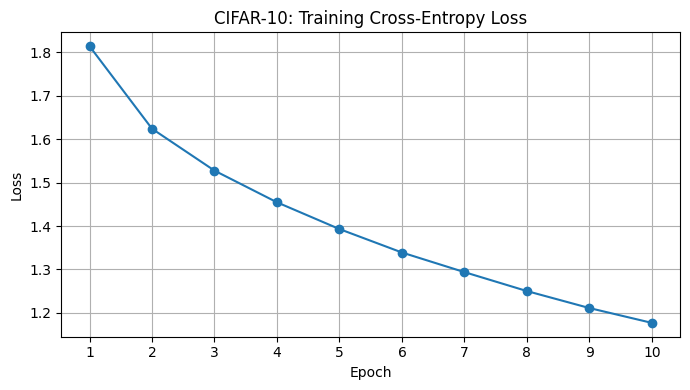

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# 1. Load CIFAR-10
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

trainset = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform
)
testset = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True, transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=50, shuffle=True,
    num_workers=2, pin_memory=(device.type == "cuda"),
    persistent_workers=True
)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=50, shuffle=False,
    num_workers=2, pin_memory=(device.type == "cuda"),
    persistent_workers=True
)

# 2. Initialize network parameters on the selected device
Din = 3 * 32 * 32
H = 100
K = 10

w1 = torch.randn(Din, H, device=device) * 0.01
b1 = torch.zeros(H, device=device)

w2 = torch.randn(H, K, device=device) * 0.01
b2 = torch.zeros(K, device=device)

epochs = 10
lr = 0.4
lr_decay = 0.9

loss_history = []

# 3. Train using manual forward propagation and backpropagation
with torch.no_grad():
    for epoch in range(epochs):
        total_loss = torch.zeros((), device=device)

        for images, labels in trainloader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            N = images.size(0)
            x = images.reshape(N, -1)
            indices = torch.arange(N, device=device)

            # Forward propagation
            h = torch.sigmoid(x @ w1 + b1)
            logits = h @ w2 + b2

            # Numerically stable log-softmax
            shifted_logits = logits - logits.max(
                dim=1, keepdim=True
            ).values

            log_probs = shifted_logits - torch.log(
                torch.exp(shifted_logits).sum(dim=1, keepdim=True)
            )

            # Cross-entropy loss
            loss = -log_probs[indices, labels].mean()
            total_loss += loss * N

            # Backpropagation: output layer
            probs = torch.exp(log_probs)
            dlogits = probs.clone()
            dlogits[indices, labels] -= 1
            dlogits /= N

            dw2 = h.T @ dlogits
            db2 = dlogits.sum(dim=0)

            # Backpropagation: sigmoid hidden layer
            dh = dlogits @ w2.T
            dz1 = dh * h * (1 - h)

            dw1 = x.T @ dz1
            db1 = dz1.sum(dim=0)

            # Gradient descent update
            w1 -= lr * dw1
            b1 -= lr * db1
            w2 -= lr * dw2
            b2 -= lr * db2

        epoch_loss = total_loss.item() / len(trainset)
        loss_history.append(epoch_loss)

        print(
            f"Epoch {epoch + 1:2d}/{epochs} | "
            f"Training Loss: {epoch_loss:.4f}"
        )

        lr *= lr_decay


# 4. Evaluate accuracy after training
@torch.no_grad()
def accuracy(loader):
    correct = torch.zeros((), dtype=torch.long, device=device)
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        x = images.reshape(images.size(0), -1)

        h = torch.sigmoid(x @ w1 + b1)
        logits = h @ w2 + b2
        predictions = logits.argmax(dim=1)

        correct += (predictions == labels).sum()
        total += labels.size(0)

    return 100 * correct.item() / total


train_acc = accuracy(trainloader)
test_acc = accuracy(testloader)

print(f"\nTraining accuracy after 10 epochs: {train_acc:.2f}%")
print(f"Test accuracy after 10 epochs: {test_acc:.2f}%")


# 5. Plot training loss
plt.figure(figsize=(7, 4))
plt.plot(range(1, epochs + 1), loss_history, "o-")
plt.title("CIFAR-10: Training Cross-Entropy Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(range(1, epochs + 1))
plt.grid(True)
plt.tight_layout()
plt.show()

A fully connected network was implemented with 3072 input features, 100 sigmoid hidden neurons, and 10 output classes. It was trained on CIFAR-10 for 10 epochs using cross-entropy loss, manual backpropagation, and gradient descent.

#### Hyperparameter Selection

The batch size was 50, and the weights were initialized with a standard deviation of 0.01. The initial learning rate was 0.4 and was multiplied by 0.9 after each epoch, allowing larger updates initially and smaller adjustments later. These settings were selected for this experiment; no systematic hyperparameter tuning was performed.

#### Expected Behaviour and Results

The loss was expected to decrease as the network learned, with training accuracy generally exceeding test accuracy.

| Metric | Result |
|---|---:|
| First-epoch training loss | 1.8136 |
| Final-epoch training loss | 1.1772 |
| Final training accuracy | 60.74% |
| Final test accuracy | 48.68% |

The training loss decreased consistently across all 10 epochs, indicating that the network learned from the training data. However, training accuracy exceeded test accuracy by **12.06 percentage points**, suggesting some overfitting.

The moderate accuracy also reflects the limitations of a small fully connected network, which does not explicitly exploit spatial image patterns like a CNN. Further improvement could be investigated by tuning the learning rate and adding regularization using a validation set.

## Question 2 – CNN-Based Image Classification on MNIST: LeNet-5 vs. Modern CNN

In [2]:

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# Dataset preparation
transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor()
])

batch_size = 50

trainset = torchvision.datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)

testset = torchvision.datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True, num_workers=0
)

testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False, num_workers=0
)

print("Training samples:", len(trainset))
print("Test samples:", len(testset))


Using: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 17.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 476kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.26MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.41MB/s]

Training samples: 60000
Test samples: 10000


In [3]:

# LeNet-5
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.pool1 = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.pool2 = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool1(torch.relu(self.conv1(x)))
        x = self.pool2(torch.relu(self.conv2(x)))

        x = torch.flatten(x, 1)
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)

        return x


# Modern 3-layer CNN with Batch Normalization and Dropout
class ModernCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(128 * 4 * 4, 10)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)

        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)

        return x


lenet = LeNet5().to(device)
modern_cnn = ModernCNN().to(device)

print("LeNet-5 parameters:",
      sum(p.numel() for p in lenet.parameters()))

print("Modern CNN parameters:",
      sum(p.numel() for p in modern_cnn.parameters()))


LeNet-5 parameters: 61706
Modern CNN parameters: 113386


In [4]:

criterion = nn.CrossEntropyLoss()
epochs = 10
learning_rate = 0.001

def evaluate(model, loader):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            predicted = outputs.argmax(dim=1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100 * correct / total


def train_model(model, name):
    optimizer = torch.optim.Adam(
        model.parameters(), lr=learning_rate
    )

    history = {
        "train_loss": [],
        "test_loss": [],
        "train_acc": [],
        "test_acc": []
    }

    for epoch in range(epochs):
        model.train()

        for images, labels in trainloader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

        train_loss, train_acc = evaluate(model, trainloader)
        test_loss, test_acc = evaluate(model, testloader)

        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)

        print(
            f"{name} | Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Test Loss: {test_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Test Acc: {test_acc:.2f}%"
        )

    return history


print("Training LeNet-5")
lenet_history = train_model(lenet, "LeNet-5")

print("\nTraining Modern CNN")
modern_history = train_model(modern_cnn, "Modern CNN")


Training LeNet-5
LeNet-5 | Epoch 1/10 | Train Loss: 0.0871 | Test Loss: 0.0811 | Train Acc: 97.27% | Test Acc: 97.52%
LeNet-5 | Epoch 2/10 | Train Loss: 0.0613 | Test Loss: 0.0592 | Train Acc: 98.03% | Test Acc: 98.20%
LeNet-5 | Epoch 3/10 | Train Loss: 0.0419 | Test Loss: 0.0417 | Train Acc: 98.64% | Test Acc: 98.64%
LeNet-5 | Epoch 4/10 | Train Loss: 0.0389 | Test Loss: 0.0473 | Train Acc: 98.71% | Test Acc: 98.56%
LeNet-5 | Epoch 5/10 | Train Loss: 0.0237 | Test Loss: 0.0355 | Train Acc: 99.27% | Test Acc: 98.88%
LeNet-5 | Epoch 6/10 | Train Loss: 0.0249 | Test Loss: 0.0375 | Train Acc: 99.24% | Test Acc: 98.75%
LeNet-5 | Epoch 7/10 | Train Loss: 0.0220 | Test Loss: 0.0445 | Train Acc: 99.23% | Test Acc: 98.56%
LeNet-5 | Epoch 8/10 | Train Loss: 0.0115 | Test Loss: 0.0324 | Train Acc: 99.65% | Test Acc: 99.03%
LeNet-5 | Epoch 9/10 | Train Loss: 0.0122 | Test Loss: 0.0380 | Train Acc: 99.60% | Test Acc: 98.88%
LeNet-5 | Epoch 10/10 | Train Loss: 0.0128 | Test Loss: 0.0454 | Train Acc

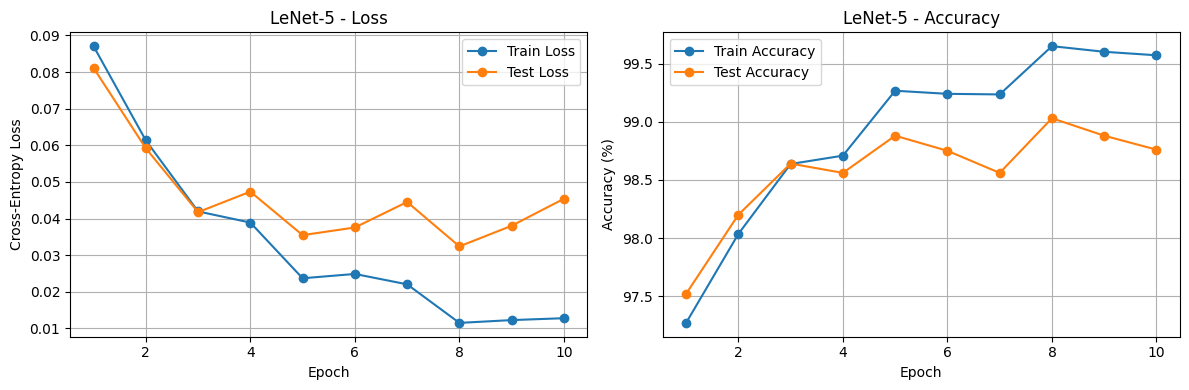

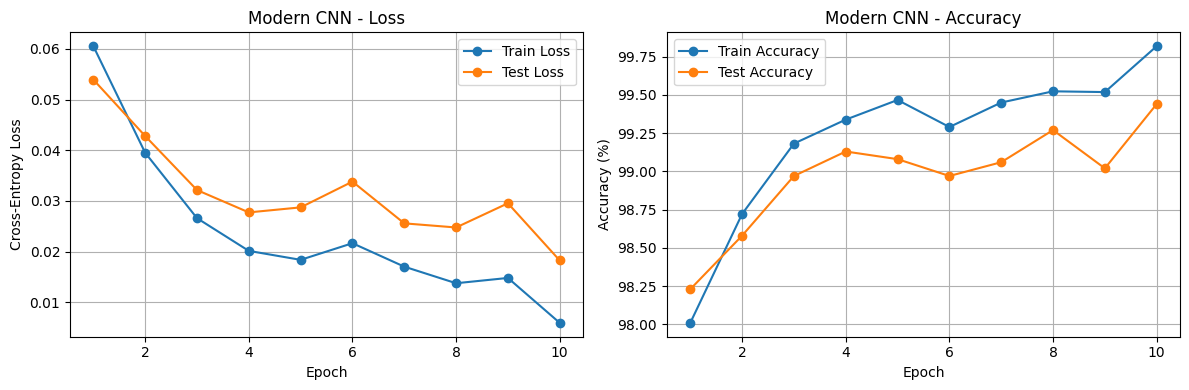

In [6]:

def plot_history(history, name):
    ep = range(1, epochs + 1)

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    ax[0].plot(ep, history["train_loss"], "-o", label="Train Loss")
    ax[0].plot(ep, history["test_loss"], "-o", label="Test Loss")
    ax[0].set_title(f"{name} - Loss")
    ax[0].set_xlabel("Epoch")
    ax[0].set_ylabel("Cross-Entropy Loss")
    ax[0].legend()
    ax[0].grid(True)

    ax[1].plot(ep, history["train_acc"], "-o", label="Train Accuracy")
    ax[1].plot(ep, history["test_acc"], "-o", label="Test Accuracy")
    ax[1].set_title(f"{name} - Accuracy")
    ax[1].set_xlabel("Epoch")
    ax[1].set_ylabel("Accuracy (%)")
    ax[1].legend()
    ax[1].grid(True)

    plt.tight_layout()
    plt.show()


plot_history(lenet_history, "LeNet-5")
plot_history(modern_history, "Modern CNN")


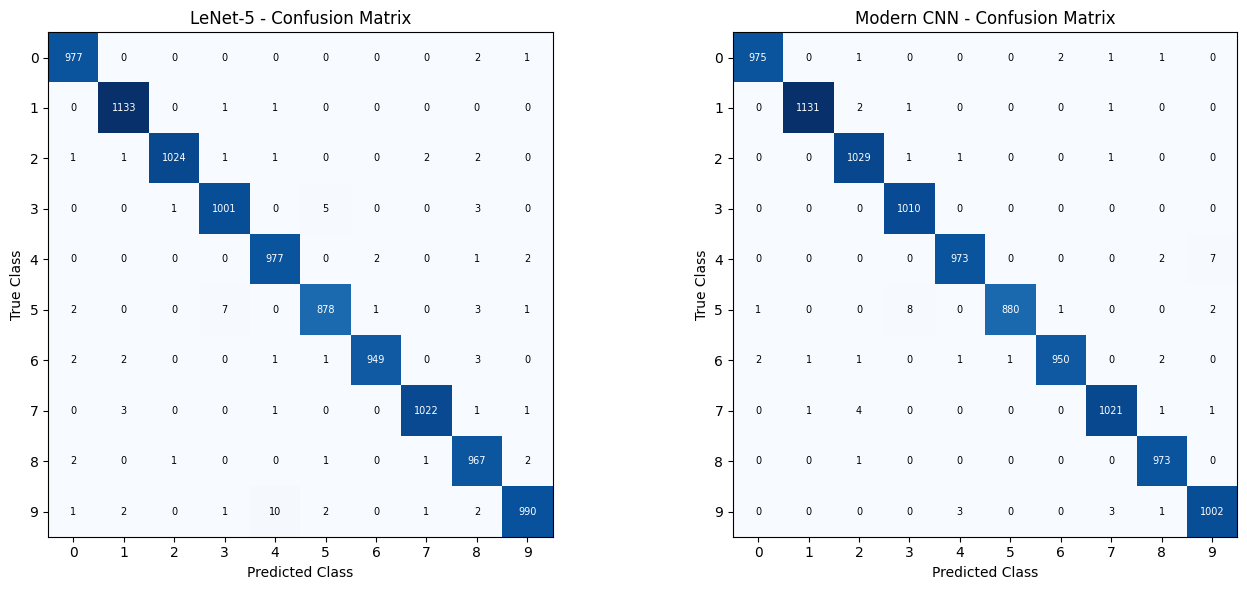

In [7]:

def get_confusion_matrix(model):
    model.eval()
    cm = np.zeros((10, 10), dtype=int)

    with torch.no_grad():
        for images, labels in testloader:
            images = images.to(device)
            outputs = model(images)

            predicted = outputs.argmax(dim=1).cpu().numpy()
            actual = labels.numpy()

            np.add.at(cm, (actual, predicted), 1)

    return cm


cm_lenet = get_confusion_matrix(lenet)
cm_modern = get_confusion_matrix(modern_cnn)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, cm, name in zip(
    axes,
    [cm_lenet, cm_modern],
    ["LeNet-5", "Modern CNN"]
):
    ax.imshow(cm, cmap="Blues")
    ax.set_title(f"{name} - Confusion Matrix")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))

    for i in range(10):
        for j in range(10):
            ax.text(
                j, i, cm[i, j],
                ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max()/2 else "black"
            )

plt.tight_layout()
plt.show()


In [8]:

print("=" * 65)
print("FINAL RESULTS AFTER 10 EPOCHS")
print("=" * 65)

print(f"{'Model':<15} {'Train Accuracy':<20} {'Test Accuracy':<20}")
print("-" * 65)

print(f"{'LeNet-5':<15} "
      f"{lenet_history['train_acc'][-1]:<20.2f} "
      f"{lenet_history['test_acc'][-1]:<20.2f}")

print(f"{'Modern CNN':<15} "
      f"{modern_history['train_acc'][-1]:<20.2f} "
      f"{modern_history['test_acc'][-1]:<20.2f}")

print("=" * 65)
print("FINAL RESULTS AFTER 10 EPOCHS")
print("=" * 65)

print(f"{'Model':<15} {'Train Accuracy':<20} {'Test Accuracy':<20}")
print("-" * 65)

print(f"{'LeNet-5':<15} "
      f"{lenet_history['train_acc'][-1]:<20.2f} "
      f"{lenet_history['test_acc'][-1]:<20.2f}")

print(f"{'Modern CNN':<15} "
      f"{modern_history['train_acc'][-1]:<20.2f} "
      f"{modern_history['test_acc'][-1]:<20.2f}")


FINAL RESULTS AFTER 10 EPOCHS
Model           Train Accuracy       Test Accuracy       
-----------------------------------------------------------------
LeNet-5         99.57                98.76               
Modern CNN      99.82                99.44               
FINAL RESULTS AFTER 10 EPOCHS
Model           Train Accuracy       Test Accuracy       
-----------------------------------------------------------------
LeNet-5         99.57                98.76               
Modern CNN      99.82                99.44               


After 10 epochs, both CNN models achieved high classification accuracies on the MNIST dataset.

| Model | Training Accuracy | Test Accuracy |
|---|---|---|
| LeNet-5 | 99.57% | 98.76% |
| Modern CNN | 99.82% | 99.44% |

The Modern CNN achieved a **0.68% higher test accuracy** than LeNet-5. Its use of batch normalization and dropout helps stabilize training and reduce overfitting.

Both confusion matrices show strong diagonal patterns, indicating that most digits were correctly classified. Some misclassifications occurred between visually similar digits, particularly **3 and 5** and **4 and 9**.

Overall, the Modern CNN demonstrated better classification performance and generalization than LeNet-5.

**Note:** The LeNet-5 confusion matrix indicates 99.18% accuracy, which differs from the reported 98.76% test accuracy.